# SBI with the library of SBI benchmark github

## Import 

In [7]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd

from sbi import analysis, utils
from sbi.inference import SNPE, simulate_for_sbi
from sbi.utils.user_input_checks import (
    check_sbi_inputs,
    process_prior,
    process_simulator,
)

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

import pyntbci

seed = 0
torch.manual_seed(seed)

In [8]:
import os
import torch

from functools import partial
from nse import NSE, NSELoss
from sm_utils import train_with_validation as train

# from tasks.jrnnm.summary import summary_JRNMM
from tasks.jrnnm.prior import prior_JRNMM
# from tasks.jrnnm.simulator import simulator_JRNMM

from tqdm import tqdm
from torch.func import vmap
from zuko.nn import MLP

from tall_posterior_sampler import diffused_tall_posterior_score, euler_sde_sampler, tweedies_approximation
from vp_diffused_priors import get_vpdiff_uniform_score

## Useful general parameter

In [9]:
PATH_EXPERIMENT = "results/flashvep/"
NUM_OBSERVATION_LIST = list(np.arange(1, 4))

N_OBS_LIST = [1, 8, 14, 22, 30]
COV_MODES = ["GAUSS", "JAC"]

torch.manual_seed(42)

In [10]:
def run_train_sgm(
    data_train,
    n_epochs,
    batch_size,
    lr,
    save_path=PATH_EXPERIMENT,
):
    # Set Device
    device = "cpu"
    if torch.cuda.is_available():
        device = "cuda:0"

    # Prepare training data
    theta_train, x_train = data_train["theta"], data_train["x"]
    # normalize theta
    theta_train_norm = (theta_train - theta_train.mean(dim=0)) / theta_train.std(dim=0)
    # normalize x
    x_train = (x_train - x_train.mean(dim=0)) / x_train.std(dim=0)
    # dataset for dataloader
    data_train = torch.utils.data.TensorDataset(
        theta_train_norm.to(device), x_train.to(device)
    )

    # Score network
    # embedding nets
    theta_dim = theta_train.shape[-1]
    x_dim = x_train.shape[-1]
    theta_embedding_net = MLP(theta_dim, 32, [64, 64, 64])
    x_embedding_net = MLP(x_dim, 32, [64, 64, 64])
    score_network = NSE(
        theta_dim=theta_dim,
        x_dim=x_dim,
        embedding_nn_theta=theta_embedding_net,
        embedding_nn_x=x_embedding_net,
        hidden_features=[256, 256, 256],
        freqs=32,
    ).to(device)

    # Train score network
    print(
        "=============================================================================="
    )
    print(
        f"Training score network: n_train = {theta_train.shape[0]}, n_epochs = {n_epochs}."
    )
    # print()
    # print(f"n_max: {n_max}, masked: {masked}, prior_score: {prior_score}")
    print(
        f"============================================================================="
    )
    print()

    # Train Score Network
    avg_score_net, train_losses, val_losses, best_epoch = train(
        score_network,
        dataset=data_train,
        loss_fn=NSELoss(score_network),
        n_epochs=n_epochs,
        lr=lr,
        batch_size=batch_size,
        # track_loss=True,
        validation_split=0.2,
        early_stopping=True,
        min_nb_epochs=n_epochs * 0.8,  # 4000
    )
    score_network = avg_score_net.module

    # Save Score Network
    os.makedirs(
        save_path,
        exist_ok=True,
    )
    torch.save(
        score_network,
        save_path + f"score_network.pkl",
    )
    torch.save(
        {
            "train_losses": train_losses,
            "val_losses": val_losses,
            "best_epoch": best_epoch,
        },
        save_path + f"train_losses.pkl",
    )

In [11]:
def run_sample_sgm(
    theta_true,
    context,
    nsamples,
    steps,  # number of ddim steps
    score_network,
    theta_train_mean,
    theta_train_std,
    x_train_mean,
    x_train_std,
    prior,
    cov_mode,
    sampler_type="ddim",
    langevin=False,
    clip=False,
    save_path=PATH_EXPERIMENT,
    single_obs=None,
    n_cal=None,
    variation=False,
):
    # Set Device
    device = "cpu"
    if torch.cuda.is_available():
        device = "cuda:0"

    # normalize context
    context_norm = (context - x_train_mean) / x_train_std

    # reshape context for calibration data if n_obs = 1
    if n_cal is None:
        n_obs = context.shape[0]
    else: 
        if context_norm.ndim < 3:
            context_norm = context_norm.unsqueeze(1)
        n_obs = context_norm.shape[1]

    # normalize prior
    low_norm = (prior.low - theta_train_mean) / theta_train_std * 2
    high_norm = (prior.high - theta_train_mean) / theta_train_std * 2
    prior_norm = torch.distributions.Uniform(low_norm.to(device), high_norm.to(device))
    prior_score_fn_norm = get_vpdiff_uniform_score(
        low_norm.to(device), high_norm.to(device), score_network.to(device)
    )

    print("=======================================================================")
    if len(theta_true) in [3,4]:
        print(
            f"Sampling from the approximate posterior at {theta_true}: n_obs = {n_obs}, nsamples = {nsamples}."
        )
    elif len(theta_true) == n_cal:
        print(
            f"Sampling from the approximate posterior at calibration data: n_obs = {n_obs}. \n x_cal shape = {context_norm.shape}."
        )
    print(f"======================================================================")
    if langevin:
        print()
        print(f"Using LANGEVIN sampler, clip = {clip}.")
        print()
        ext = ""
        theta_clipping_range = (None, None)
        if clip:
            theta_clipping_range = (-3, 3)
            ext = "_clip"
        # samples = score_network.predictor_corrector(
        #     (nsamples,),
        #     x=context_norm.to(device),
        #     steps=400,
        #     prior_score_fun=prior_score_fn_norm,
        #     lsteps=5,
        #     r=0.5,
        #     predictor_type="id",
        #     verbose=True,
        #     theta_clipping_range=theta_clipping_range,
        # ).cpu()
        sampler = lambda x: score_network.annealed_langevin_geffner(
            shape=(nsamples,),
            x=x.to(device),
            prior_score_fn=prior_score_fn_norm,
            steps=400,
            lsteps=5,
            tau=0.5,
            theta_clipping_range=theta_clipping_range,
            verbose=True,
        )
        if n_cal is None:
            samples = sampler(context_norm.to(device)).cpu()
        else:
            assert n_cal == context_norm.shape[0]
            samples = vmap(sampler, randomness="different")(context_norm.to(device)).squeeze(1).cpu()
        
        # save  path
        save_path += f"langevin_steps_400_5/"
        if variation:
            save_path += f"variate/"
        else:
            save_path += f"nonvariate/"
        if n_cal is None:
            if single_obs is not None:
                save_path += f"single_obs/"
                samples_filename = (
                    save_path
                    + f"num_{single_obs}_posterior_samples_{np.round(theta_true.tolist(),decimals=3)}_n_obs_{n_obs}{ext}.pkl"
                )
            else:
                samples_filename = (
                    save_path
                    + f"posterior_samples_{np.round(theta_true.tolist(),decimals=3)}_n_obs_{n_obs}{ext}.pkl"
                )
        else:
            samples_filename = (
                save_path
                + f"posterior_samples_n_cal_{n_cal}_n_obs_{n_obs}{ext}.pkl"
            )

    else:
        print()
        print(
            f"Using {sampler_type.upper()} sampler, cov_mode = {cov_mode}, clip = {clip}."
        )
        print()

        cov_mode_name = cov_mode
        theta_clipping_range = (None, None)
        if clip:
            theta_clipping_range = (-3, 3)
            cov_mode_name += "_clip"

        cov_est = None
        if cov_mode == "GAUSS":
            # estimate cov
            cov_est_fn = lambda x: score_network.ddim(shape=(1000,), x=x, steps=100, eta=0.5)
            if n_cal is None:
                cov_est = vmap(cov_est_fn, randomness="different")(context_norm.to(device))
                cov_est = vmap(lambda x: torch.cov(x.mT))(cov_est)
            else:
                # commented part yields cuda memory error (on drago3)
                # print(f"Estimating Covariance on Calibration Data of size {context_norm.shape[0]}...")
                # cov_est = vmap(vmap(
                #     cov_est_fn,
                #     randomness="different",
                # ), randomness='different')(context_norm.to(device))

                # split context into batches
                b_size = 2000 if n_obs == 1 else 200 if n_obs == 8 else 100 if n_obs == 14 else 50 if n_obs in [22, 30] else 1
                context_norm_b = context_norm.reshape(-1, b_size, n_obs, context_norm.shape[-1])
                cov_est = []
                for batch in tqdm(context_norm_b, desc="Estimating Covariance on calibration data over batches"):
                    cov_ = vmap(vmap(
                        cov_est_fn,
                        randomness="different",
                    ), randomness='different')(batch.to(device))
                    assert torch.isnan(cov_).sum() == 0, f"Number of NaNs in cov est: {torch.isnan(cov_).sum()}, {torch.where(torch.isnan(cov_))}"
                    cov_est.append(cov_)
                cov_est = torch.cat(cov_est, dim=0)
                cov_est = vmap(vmap(lambda x: torch.cov(x.mT)))(cov_est)
            assert torch.isnan(cov_est).sum() == 0, f"Number of NaNs in cov est: {torch.isnan(cov_est).sum()}, {torch.where(torch.isnan(cov_est))}"
            print(f"cov est shape: {cov_est.shape}")
            print()

        if sampler_type == "ddim":
            save_path += f"ddim_steps_{steps}/"
            if variation:
                save_path += f"variate/"
            else:
                save_path += f"nonvariate/"

            sampler = lambda x, cov_est: score_network.ddim(
                shape=(nsamples,),
                x=x.to(device),
                eta=1
                if steps == 1000
                else 0.8
                if steps == 400
                else 0.5,  # corresponds to the equivalent time setting from section 4.1
                steps=steps,
                theta_clipping_range=theta_clipping_range,
                prior=prior_norm,
                prior_type="uniform",
                prior_score_fn=prior_score_fn_norm,
                dist_cov_est=cov_est,
                cov_mode=cov_mode,
                verbose=True,
            )

            if n_cal is None:
                samples = sampler(context_norm.to(device), cov_est).cpu()
            else:
                assert n_cal == context_norm.shape[0]
                print(f"Sampling from tall posterior on each of the {n_cal} observations from the calibration data...")
                if cov_mode == "GAUSS":
                    samples = vmap(sampler, randomness='different')(context_norm.to(device), cov_est).squeeze(1).cpu()
                else:
                    samples = vmap(partial(sampler, cov_est=None), randomness='different')(context_norm.to(device)).squeeze(1).cpu()
            
        else:
            if n_cal is not None:
                raise NotImplementedError
        
            save_path += f"euler_steps_{steps}/"
            if variation:
                save_path += f"variate/"
            else:
                save_path += f"nonvariate/"
            # define score function for tall posterior
            score_fn = partial(
                diffused_tall_posterior_score,
                prior_type="uniform",
                prior=None,
                prior_score_fn=prior_score_fn_norm,  # analytical prior score function
                x_obs=context_norm.to(device),  # observations
                nse=score_network,  # trained score network
                dist_cov_est=cov_est,
                cov_mode=cov_mode,
            )
            # sample from tall posterior
            (
                samples,
                _,
            ) = euler_sde_sampler(
                score_fn,
                nsamples,
                dim_theta=len(theta_true),
                beta=score_network.beta,
                device=device,
                debug=False,
                theta_clipping_range=theta_clipping_range,
            )

        # save  path
        if n_cal is None:
            if single_obs is not None:
                save_path += f"single_obs/"
                samples_filename = (
                    save_path
                    + f"num_{single_obs}_posterior_samples_{np.round(theta_true.tolist(),decimals=3)}_n_obs_{n_obs}_{cov_mode_name}.pkl"
                )
            else:
                samples_filename = (
                    save_path
                    + f"posterior_samples_{np.round(theta_true.tolist(),decimals=3)}_n_obs_{n_obs}_{cov_mode_name}.pkl"
                )
        else:
            samples_filename = (
                save_path
                + f"posterior_samples_n_cal_{n_cal}_n_obs_{n_obs}_{cov_mode_name}.pkl"
            )

    if torch.isnan(samples).sum() != 0:
        print(f"Number of NaNs in samples: {torch.isnan(samples).sum()}, {torch.where(torch.isnan(samples))}")
        # replace NaNs with mean if it's less than 10% of the samples
        theshold = 0.1 * samples.shape[0] * samples.shape[1]
        if torch.isnan(samples).sum() < int(0.1*samples.shape[0]):
            samples_new = torch.where(torch.isnan(samples),0,samples)
            samples = torch.where(samples_new == 0,samples_new.mean(axis=0), samples_new)

    assert torch.isnan(samples).sum() == 0, f"Number of NaNs in samples: {torch.isnan(samples).sum()}, {torch.where(torch.isnan(samples))}"

    # unnormalize
    samples = samples.detach().cpu()
    samples = samples * theta_train_std + theta_train_mean

    # save  results
    os.makedirs(
        save_path,
        exist_ok=True,
    )
    torch.save(samples, samples_filename)

    print(f"samples shape: {samples.shape}")
    print(f"Saved samples to {samples_filename}.")

In [31]:
def run(n_obs, run_type,n_train,n_epochs,lr,batch_size,single_obs,nsamples,steps,cov_mode,sampler,langevin,clip,n_cal,variation,theta_true=None):
        # Define Experiment Path
        save_path = (
            PATH_EXPERIMENT
            + f"n_train_{n_train}_n_epochs_{n_epochs}_lr_{lr}/"
        )
        os.makedirs(save_path, exist_ok=True)

        print()
        print("save_path: ", save_path)
        print("CUDA available: ", torch.cuda.is_available())
        print()

        # SBI Task: prior and simulator
        # amplitude | width | lantecy | noise
        parameters = np.array([(0.5, 2.0), (0.005, 0.05), (0.05, 0.5), (0.0,0.5)])

        prior = prior_FlashVep(parameters)
        simulator = partial(simulator_model)

        # # Summary features
        # summary_extractor = summary_JRNMM()
        # # let's use the *log* power spectral density
        # summary_extractor.embedding.net.logscale = True

        # Simulate Training Data
        filename = PATH_EXPERIMENT + f"dataset_n_train_"+str(n_train)+".pkl"
        if os.path.exists(filename):
            dataset_train = torch.load(filename)
            theta_train = dataset_train["theta"][: n_train]
            x_train = dataset_train["x"][: n_train]
            print(x_train.dtype)
        else:
            print("==============================================================================")
            print(f"Sampling training data.")
            print(f"======================================================================")
            theta_train = prior.sample((n_train,)).to(torch.float32)
            x_train = simulator(theta_train).to(torch.float32)

            dataset_train = {
                "theta": theta_train, "x": x_train
            }
            torch.save(dataset_train, filename)
            dataset_train = torch.load(filename)
            theta_train = dataset_train["theta"][: n_train].to(torch.float32)
            x_train = dataset_train["x"][: n_train].to(torch.float32)
        
        theta_train_mean = theta_train.mean(dim=0)
        theta_train_std = theta_train.std(dim=0)
        x_train_mean = x_train.mean(dim=0)
        x_train_std = x_train.std(dim=0)
        means_stds_dict = {
            "theta_train_mean": theta_train_mean,
            "theta_train_std": theta_train_std,
            "x_train_mean": x_train_mean,
            "x_train_std": x_train_std,
        }
        torch.save(means_stds_dict, save_path + f"train_means_stds_dict.pkl")

        if run_type == "train":
            run_fn = run_train_sgm
            kwargs_run = {
                "data_train": dataset_train,
                "n_epochs": n_epochs,
                "batch_size": batch_size,
                "lr": lr,
                "save_path": save_path,
            }
        elif run_type == "sample" or run_type == "sample_cal":
            # Trained Score network
            score_network = torch.load(
                save_path + f"score_network.pkl",
                map_location=torch.device("cpu"),
            )
            score_network.net_type = "default"
            score_network.tweedies_approximator = tweedies_approximation

            # Mean and std of training data
            means_stds_dict = torch.load(save_path + f"train_means_stds_dict.pkl")
            theta_train_mean = means_stds_dict["theta_train_mean"]
            theta_train_std = means_stds_dict["theta_train_std"]
            x_train_mean = means_stds_dict["x_train_mean"]
            x_train_std = means_stds_dict["x_train_std"]

            if run_type == "sample":
                # Reference parameter and observations
                if theta_true is None:
                    theta_true = torch.tensor([1., 0.02, 0.2,0.08]).to(torch.float32)
                if variation:
                    filename = PATH_EXPERIMENT + f"x_obs_100_{np.round(theta_true.tolist(),decimals=3)}_variate.pkl"
                else:
                    filename = PATH_EXPERIMENT + f"x_obs_100_{np.round(theta_true.tolist(),decimals=3)}.pkl"

                if os.path.exists(filename):
                    x_obs_100 = torch.load(filename).to(torch.float32)
                else:
                    if variation:
                        x_obs_100 = torch.cat(
                            [simulator(theta_true+torch.cat([torch.rand(1)*0.1-0.05+theta_true[0],
                                                            torch.rand(1)*0.001-0.0005+theta_true[1],
                                                            torch.rand(1)*0.01-0.005+theta_true[2],
                                                            torch.rand(1)*0.01-0.005+theta_true[3]])).to(torch.float32) for _ in tqdm(range(100))], dim=0
                        )
                    else:
                        x_obs_100 = torch.cat(
                            [simulator(theta_true).to(torch.float32) for _ in tqdm(range(100))], dim=0
                        )
                    torch.save(x_obs_100, filename)

                if single_obs:
                    for i, x_obs in enumerate(x_obs_100[:n_obs]):
                        run_fn = run_sample_sgm
                        kwargs_run = {
                            "theta_true": theta_true,
                            "context": x_obs.unsqueeze(0),
                            "nsamples": nsamples,
                            "score_network": score_network,
                            "steps": steps,
                            "theta_train_mean": theta_train_mean,  # for (un)normalization
                            "theta_train_std": theta_train_std,  # for (un)normalization
                            "x_train_mean": x_train_mean,  # for (un)normalization
                            "x_train_std": x_train_std,  # for (un)normalization
                            "prior": prior,  # for score function
                            "cov_mode": cov_mode,
                            "sampler_type": sampler,
                            "langevin": langevin,
                            "clip": clip,
                            "save_path": save_path,
                            "single_obs": i,
                            "variation": variation,
                        }
                        run_fn(**kwargs_run)
                    run_fn = lambda **kwargs: None
                else:
                    run_fn = run_sample_sgm
                    kwargs_run = {
                        "theta_true": theta_true,
                        "context": x_obs_100[:n_obs],
                        "nsamples": nsamples,
                        "score_network": score_network,
                        "steps": 1000
                        if cov_mode == "GAUSS"
                        else 400,  # corresponds to the equivalent time setting from section 4.1
                        "theta_train_mean": theta_train_mean,  # for (un)normalization
                        "theta_train_std": theta_train_std,  # for (un)normalization
                        "x_train_mean": x_train_mean,  # for (un)normalization
                        "x_train_std": x_train_std,  # for (un)normalization
                        "prior": prior,  # for score function
                        "cov_mode": cov_mode,
                        "sampler_type": sampler,
                        "langevin": langevin,
                        "clip": clip,
                        "save_path": save_path,
                        "variation": variation,
                    }

            elif run_type == "sample_cal":
                # Simulate Calibration Data
                filename = PATH_EXPERIMENT + f"dataset_n_cal_10000_n_obs_{n_obs}.pkl"
                if os.path.exists(filename):
                    dataset_cal = torch.load(filename)
                else:
                    print("==============================================================================")
                    print(f"Sampling calibration data for n_obs = {n_obs}.")
                    print(f"======================================================================")
                    theta_cal = prior.sample((10000,)).to(torch.float32)
                    theta_cal_big = theta_cal.repeat(n_obs, 1)
                    x_cal = simulator(theta_cal_big).to(torch.float32)
                    if n_obs > 1:
                        x_cal = x_cal.reshape(n_obs, n_cal, -1).permute(1, 0, 2) # (n_cal, n_obs, x_dim)
                    print(x_cal.shape)

                    dataset_cal = {
                        "theta": theta_cal, "x": x_cal
                    }
                    torch.save(dataset_cal, filename)
                theta_cal = dataset_cal["theta"][: n_cal]
                x_cal = dataset_cal["x"][: n_cal]

                run_fn = run_sample_sgm
                kwargs_run = {
                    "theta_true": theta_cal,
                    "context": x_cal,
                    "nsamples": 1,
                    "score_network": score_network,
                    "steps": 1000
                    if cov_mode == "GAUSS"
                    else 400,  # corresponds to the equivalent time setting from section 4.1
                    "theta_train_mean": theta_train_mean,  # for (un)normalization
                    "theta_train_std": theta_train_std,  # for (un)normalization
                    "x_train_mean": x_train_mean,  # for (un)normalization
                    "x_train_std": x_train_std,  # for (un)normalization
                    "prior": prior,  # for score function
                    "cov_mode": cov_mode,
                    "sampler_type": sampler,
                    "langevin": langevin,
                    "clip": clip,
                    "save_path": save_path,
                    "n_cal": n_cal,
                }

        
        run_fn(**kwargs_run)

## Model and task

In [32]:
def simulator_model(theta,code=0):
    if theta.ndim == 1:
        return simulator_model(
            theta.view(1, -1),
            code
        )
    x = []

    for thetai in theta:
        fs = 500  # Hertz
        pr = 60  # Hertz
        amplitude = thetai[0]  # microvolts
        width = thetai[1]  # seconds
        latency = thetai[2]  # seconds
        encoding_length = 0.4  # seconds
        n_channels = 1
        snr = thetai[3]
        # code = parameter[4]

        # Generate codes
        V = pyntbci.stimulus.make_gold_codes()
        V = pyntbci.stimulus.modulate(V)
        V = V.repeat(int(fs / pr), axis=1)
        n_codes, n_samples = V.shape

        # Generate structure matrices
        M = torch.Tensor(pyntbci.utilities.encoding_matrix(V[:, np.newaxis, :], int(encoding_length * fs)))

        # Generate flash-VEP
        time = torch.Tensor(np.arange(0, encoding_length, 1/fs))
        r = amplitude * (1 - ((time - latency) / width)**2) * np.exp(-0.5 * ((time - latency) / width)**2)

        # Generate template responses
        # print(r.unsqueeze(1).shape)
        # print(M.transpose(1, 0).reshape((-1, n_codes * n_samples)).shape)
        T = r.matmul(M.transpose(1, 0).reshape((-1, n_codes * n_samples))).reshape(n_codes, n_samples)
        # T /= T.std(axis=1, keepdims=True)  # normalize amplitudes

        noise=0
        sig_avg = torch.mean(T**2,axis=1)
        sig_avg_db = 10 * np.log10(sig_avg)
        # Calculate noise according to [2] then convert to watts
        noise_avg_db = sig_avg_db - 1/snr
        noise_avg = 10 ** (noise_avg_db / 10)
        # Generate an sample of white noise
        mean_noise = 0
        noise = np.random.normal(mean_noise, np.sqrt(torch.mean(noise_avg)), T[code].shape)

        x.append(T[code]+noise)
    
    return torch.stack(x)

In [33]:
class prior_FlashVep(utils.BoxUniform):
    def __init__(self, parameters=np.array([(0.5, 2.0), (0.005, 0.05), (0.05, 0.5), (0.0,0.5)])):
        self.parameters = parameters

        self.bounds = [[param[0], param[1]] for param in parameters]

        self.low = torch.tensor([v[0] for v in self.bounds])
        self.high = torch.tensor([v[1] for v in self.bounds])

        super().__init__(low=self.low, high=self.high)

## Initialize parameters

In [34]:
n_train = 50000
batch_size = 256
n_epochs = 5000
lr = 1e-4
clf_free_guidance = False
n_obs = 2
single_obs = False
n_samples= 5000
steps = 1000
cov_mode = "GAUSS"
sampler= "ddim"
langevin = False
clip = True
n_cal = 10000
variation = True
theta_true = torch.tensor([1., 0.02, 0.2,0.08]).to(torch.float32)

# Define Experiment Path
save_path = (
    "D:/s.velut/Documents/These/DCC/SBI/FlashVEP/FlashVEP"
    + f"n_train_{n_train}_bs_{batch_size}_n_epochs_{n_epochs}_lr_{lr}/"
)
os.makedirs(save_path, exist_ok=True)

## Train the algorithm

In [21]:
run_type="train"

run(n_obs,run_type,n_train,n_epochs,lr,batch_size,single_obs,n_samples,steps,cov_mode,sampler,langevin,clip,n_cal,variation)

print()
print("save_path: ", save_path)
print("CUDA available: ", torch.cuda.is_available())
print()


save_path:  results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/
CUDA available:  False

Sampling training data.


C:\Users\s.velut\AppData\Local\Temp\ipykernel_26260\2137620346.py:41: RuntimeWarning: divide by zero encountered in log10
  sig_avg_db = 10 * np.log10(sig_avg)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_26260\2049464894.py:44: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of 

Training score network: n_train = 50000, n_epochs = 5000.



Training epochs: 100%|██████████| 5000/5000 [2:39:06<00:00,  1.91s/it, lr=0.0001, train_loss=0.0555, val_loss=0.187]  

EARLY STOPPING: best validation loss 0.16134386618137359 at epoch 4911
Did not improve for 89 epochs

save_path:  D:/s.velut/Documents/These/DCC/SBI/FlashVEP/FlashVEPn_train_50000_bs_256_n_epochs_5000_lr_0.0001/
CUDA available:  False



## Sample things

In [36]:
run_type="sample"

for n in N_OBS_LIST:
    run(n,run_type,n_train,n_epochs,lr,batch_size,single_obs,n_samples,steps,cov_mode,sampler,langevin,clip,n_cal,variation)



save_path:  results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/
CUDA available:  False

torch.float32
Sampling from the approximate posterior at tensor([1.0000, 0.0200, 0.2000, 0.0800]): n_obs = 1, nsamples = 5000.

Using DDIM sampler, cov_mode = GAUSS, clip = True.



C:\Users\s.velut\AppData\Local\Temp\ipykernel_21736\2937163889.py:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  dataset_train = torch.load(filename)
C:\Users\s.velut\App

cov est shape: torch.Size([1, 4, 4])



100%|██████████| 1000/1000 [00:08<00:00, 115.44it/s]


samples shape: torch.Size([5000, 4])
Saved samples to results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/ddim_steps_1000/variate/posterior_samples_[1.   0.02 0.2  0.08]_n_obs_1_GAUSS_clip.pkl.

save_path:  results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/
CUDA available:  False

torch.float32
Sampling from the approximate posterior at tensor([1.0000, 0.0200, 0.2000, 0.0800]): n_obs = 8, nsamples = 5000.

Using DDIM sampler, cov_mode = GAUSS, clip = True.

cov est shape: torch.Size([8, 4, 4])



100%|██████████| 1000/1000 [01:09<00:00, 14.44it/s]


... (3 outputs left out)

100%|██████████| 1000/1000 [04:08<00:00,  4.03it/s]


samples shape: torch.Size([5000, 4])
Saved samples to results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/ddim_steps_1000/variate/posterior_samples_[1.   0.02 0.2  0.08]_n_obs_22_GAUSS_clip.pkl.

save_path:  results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/
CUDA available:  False

torch.float32
Sampling from the approximate posterior at tensor([1.0000, 0.0200, 0.2000, 0.0800]): n_obs = 30, nsamples = 5000.

Using DDIM sampler, cov_mode = GAUSS, clip = True.

cov est shape: torch.Size([30, 4, 4])



100%|██████████| 1000/1000 [05:24<00:00,  3.08it/s]

samples shape: torch.Size([5000, 4])
Saved samples to results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/ddim_steps_1000/variate/posterior_samples_[1.   0.02 0.2  0.08]_n_obs_30_GAUSS_clip.pkl.


In [37]:
# x = torch.load("D:/s.velut/Documents/These/DCC/SBI/results/flashvep/x_obs_100_[1.   0.02 0.3  0.08].pkl")
# for i in range(10):
#     plt.plot(x[i])

In [38]:
# theta1 = torch.load("D:/s.velut/Documents/These/DCC/SBI/results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/ddim_steps_1000/posterior_samples_[1.   0.02 0.3  0.08]_n_obs_1_GAUSS_clip.pkl")
# theta2 = torch.load("D:/s.velut/Documents/These/DCC/SBI/results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/ddim_steps_1000/posterior_samples_[1.   0.02 0.3  0.08]_n_obs_14_GAUSS_clip.pkl")
# theta3 = torch.load("D:/s.velut/Documents/These/DCC/SBI/results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/ddim_steps_1000/posterior_samples_[1.   0.02 0.3  0.08]_n_obs_30_GAUSS_clip.pkl")
# theta_true = torch.Tensor([1., 0.02, 0.3,0.08])

In [24]:
print((theta1 - theta_true).abs().mean(dim=0))
print((theta2 - theta_true).abs().mean(dim=0))
print((theta3 - theta_true).abs().mean(dim=0))

tensor([0.0155, 0.0005, 0.0015, 0.0197])
tensor([0.0149, 0.0004, 0.0017, 0.0086])
tensor([0.0142, 0.0003, 0.0017, 0.0088])


## Plot rsults

In [39]:
import torch
import matplotlib.pyplot as plt
import numpy as np

# from ot import sliced_wasserstein_distance
from experiment_utils import dist_to_dirac
from plot_utils import (
    METHODS_STYLE,
    METRICS_STYLE,
    set_plotting_style,
    plot_pairgrid_with_groundtruth_jrnnm,
)

In [40]:
def load_losses(lr=lr, n_epochs=n_epochs,n_train=n_train):
    filename = (
        PATH_EXPERIMENT
        + f"n_train_{n_train}_n_epochs_{n_epochs}_lr_{lr}/train_losses.pkl"
    )
    losses = torch.load(filename)
    train_losses = losses["train_losses"]
    val_losses = losses["val_losses"]
    best_epoch = losses["best_epoch"]
    return train_losses, val_losses, best_epoch

def load_results(
    result_name,
    n_obs,
    lr=lr,
    n_epochs=n_epochs,
    n_train=n_train,
    cov_mode=None,
    sampler="ddim",
    langevin=False,
    clip=False,
    single_obs=None,
    variation=False,
    theta_true = [1.,0.02,0.3,0.08]
):
    path = PATH_EXPERIMENT + f"n_train_{n_train}_n_epochs_{n_epochs}_lr_{lr}/"
    if langevin:
        path = path + "langevin_steps_400_5/"
    else:
        path = (
            path + f"{sampler}_steps_1000/"
            if sampler == "euler" or cov_mode == "GAUSS"
            else path + f"{sampler}_steps_400/"
        )
    if variation:
        path = path+"variate/"
    else:
        path = path+"nonvariate/"
    if single_obs is not None:
        path = (
            path + f"single_obs/num_{single_obs}_" + result_name + f"_{np.round(torch.tensor(theta_true).to(torch.float32).tolist(),decimals=3)}_n_obs_1.pkl"
        )
    else:
        path = path + result_name + f"_{np.round(torch.tensor(theta_true).to(torch.float32).tolist(),decimals=3)}_n_obs_{n_obs}.pkl"
    if not langevin:
        path = path[:-4] + f"_{cov_mode}.pkl"
    if clip:
        path = path[:-4] + "_clip.pkl"
    results = torch.load(path)
    return results

# compute mean distance to true theta over all observations
def compute_distance_to_true_theta(cov_mode=None, langevin=False, clip=False, variation=False,theta_true=[1., 0.02, 0.2,0.08]
):
    dist_dict = dict(zip(N_OBS_LIST, [[]] * len(N_OBS_LIST)))
    for n_obs in N_OBS_LIST:
        samples = load_results(
            result_name="posterior_samples",
            n_obs=n_obs,
            cov_mode=cov_mode,
            langevin=langevin,
            clip=clip,
            variation=variation,
            theta_true=theta_true,
        )
        dist_dict[n_obs] = dist_to_dirac(
            samples, torch.tensor(theta_true), metrics=["mmd"], scaled=True
        )
    return dist_dict

In [41]:
alpha, alpha_fill = set_plotting_style()
# method_names = ["GAUSS", "GAUSS_clip", "LANGEVIN", "LANGEVIN_clip", "JAC", "JAC_clip"]
method_names = ["GAUSS_clip"]
losses = True
dirac_dist = True
pairplot = True
prefix = "_variate" if variation else "_nonvariate"

if losses:
    # plot losses function to select lr
    # lr_list = [1e-4, 1e-3]
    lr_list = [1e-4,]
    fig, axs = plt.subplots(1, 1, figsize=(10, 5), sharey=True)
    fig.subplots_adjust(
        right=0.995, top=0.92, bottom=0.2, hspace=0, wspace=0, left=0.2
    )
    best_val_loss = {}
    for lr_, c in zip(lr_list, ["blue", "orange"]):
        train_losses, val_losses, best_epoch = load_losses(
            lr_, n_epochs=n_epochs
        )
        best_val_loss[lr_] = val_losses[best_epoch]
        axs.plot(
            train_losses,
            label=f"train (lr={lr_})",
            color=c,
            linewidth=3,
            alpha=0.3,
        )
        axs.plot(val_losses, label=f"val", color=c, linewidth=3, alpha=0.9)
        axs.axvline(
            best_epoch,
            color=c,
            linestyle="--",
            linewidth=5,
            alpha=0.9,
            zorder=10000,
        )
    # print(best_val_loss)
    # get lr for min best val loss
    best_lr = min(best_val_loss, key=best_val_loss.get)
    # print(f"best lr for {dim}D: {best_lr}")
    axs.set_title(rf"${4}$D")  # + f" \n best_lr={best_lr}")
    # axs.set_ylim([0, 0.5])
    # axs.set_xlim([0, 5000])
    axs.set_xlabel("epochs")
    # axs[i].set_ylabel("loss")
    axs.legend()
    plt.savefig(PATH_EXPERIMENT + "jrnnm_losses"+prefix+".png")
    plt.savefig(PATH_EXPERIMENT + "jrnnm_losses"+prefix+".pdf")
    plt.clf()

if dirac_dist:

    # plot mean distance to true theta as function of n_obs
    fig, axs = plt.subplots(1, 1, figsize=(5, 5))
    fig.subplots_adjust(
        right=0.995, top=0.92, bottom=0.2, hspace=0, wspace=0, left=0.25
    )
    for method in method_names:
        if method == "JAC":
            continue
        else:
            dist_dict = compute_distance_to_true_theta(
                cov_mode=method.split("_")[0],
                        langevin=True if "LANGEVIN" in method else False,
                        clip=True if "clip" in method else False,
                        variation=variation,
                        theta_true=theta_true,
                    )
            axs.plot(
                N_OBS_LIST,
                [dist_dict[n_obs]["mmd"] for n_obs in N_OBS_LIST],
                alpha=alpha,
                **METHODS_STYLE[method],
            )
    axs.set_xticks(N_OBS_LIST)
    axs.set_xlabel(r"$n$")
    # axs.set_ylabel(f"{METRICS_STYLE[metric]['label']}")

    # plt.suptitle(rf"MMD to $\theta^\star = (135, 220, 2000, {gain})$")
    plt.savefig(PATH_EXPERIMENT + f"mmd_to_dirac_n_obs"+prefix+".png")
    plt.savefig(PATH_EXPERIMENT + f"mmd_to_dirac_n_obs"+prefix+".pdf")
    plt.clf()
if pairplot:
    from matplotlib import colormaps as cm

    method = "GAUSS_clip"
    # theta_true = [1., 0.02, 0.3,0.08]
    samples = []
    labels = []
    for n_obs in N_OBS_LIST:
        samples_ = load_results(
            result_name="posterior_samples",
            n_obs=n_obs,
            cov_mode=method.split("_")[0],
            langevin=True if "LANGEVIN" in method else False,
            clip=True if "clip" in method else False,
            variation=variation,
            theta_true=theta_true
        )
        samples.append(samples_)
        labels.append(rf"$n={n_obs}$")
    colors = [
        cm.get_cmap("viridis")(i) for i in torch.linspace(0.2, 1, len(N_OBS_LIST))
    ]
    plot_pairgrid_with_groundtruth_jrnnm(samples, [theta_true], labels, colors)
    plt.savefig(PATH_EXPERIMENT + f"pairplot_{method}"+prefix+".png")
    plt.savefig(PATH_EXPERIMENT + f"pairplot_{method}"+prefix+".pdf")
    plt.clf()

C:\Users\s.velut\AppData\Local\Temp\ipykernel_21736\1624677373.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  losses = torch.load(filename)


C:\Users\s.velut\AppData\Local\Temp\ipykernel_21736\1624677373.py:44: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  path = path + result_name + f"_{np.round(torch.tensor(theta_true).to(torch.float32).tolist(),decimals=3)}_n_obs_{n_obs}.pkl"
C:\Users\s.velut\AppData\Local\Temp\ipykernel_21736\1624677373.py:49: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be al

<Figure size 1000x500 with 0 Axes>

<Figure size 500x500 with 0 Axes>

<Figure size 1012.21x800 with 0 Axes>

## For several theta_true

In [42]:
run_type="sample"
(0.5, 2.0), (0.005, 0.05), (0.05, 0.5), (0.0,0.5)
theta_true_list = [torch.tensor([0.5, 0.005, 0.05,0.0]).to(torch.float32),torch.tensor([0.7, 0.01, 0.1,0.05]).to(torch.float32),
                   torch.tensor([0.9, 0.015, 0.15,0.1]).to(torch.float32),torch.tensor([1.1, 0.02, 0.2,0.15]).to(torch.float32),
                   torch.tensor([1.3, 0.025, 0.25,0.2]).to(torch.float32),torch.tensor([1.5, 0.03, 0.3,0.25]).to(torch.float32),
                   torch.tensor([1.7, 0.035, 0.35,0.3]).to(torch.float32),torch.tensor([1.9, 0.04, 0.4,0.35]).to(torch.float32),]

theta1range = np.arange(0.5,2.0,0.1) 
theta2range = np.arange(0.005,0.05,0.005) 
theta3range = np.arange(0.05,0.5,0.1) 
theta4range = np.arange(0.0,0.5,0.1) 

prefix = "_variate" if variation else ""

obs_df = pd.DataFrame(columns=["amplitude","width","latency","noise","results"])

for t1 in theta1range:
    if os.path.exists(f"D:/s.velut/Documents/These/DCC/SBI/results/flashvep/x_obs_100_{np.round(torch.tensor([t1,0.02, 0.2,0.1]).to(torch.float32).tolist(),decimals=3)}"+prefix+".pkl"):
        print("pass to next")
        pass
    else:
        run(8,run_type,n_train,n_epochs,lr,batch_size,single_obs,n_samples,
            steps,cov_mode,sampler,langevin,clip,n_cal,variation,torch.tensor([t1,0.02, 0.2,0.1]).to(torch.float32))

for t2 in theta2range:
    if os.path.exists(f"D:/s.velut/Documents/These/DCC/SBI/results/flashvep/x_obs_100_{np.round(torch.tensor([1.0,t2,0.2,0.1]).to(torch.float32).tolist(),decimals=3)}"+prefix+".pkl"):
        print("pass to next")
        pass
    else:
        run(8,run_type,n_train,n_epochs,lr,batch_size,single_obs,n_samples,
            steps,cov_mode,sampler,langevin,clip,n_cal,variation,torch.tensor([1.0,t2,0.2,0.1]).to(torch.float32))

for t3 in theta3range:
    if os.path.exists(f"D:/s.velut/Documents/These/DCC/SBI/results/flashvep/x_obs_100_{np.round(torch.tensor([1.0,0.02,t3,0.1]).to(torch.float32).tolist(),decimals=3)}"+prefix+".pkl"):
        print("pass to next")
        pass
    else:
        run(8,run_type,n_train,n_epochs,lr,batch_size,single_obs,n_samples,
            steps,cov_mode,sampler,langevin,clip,n_cal,variation,torch.tensor([1.0,0.02,t3,0.1]).to(torch.float32))

for t4 in theta4range:
    if os.path.exists(f"D:/s.velut/Documents/These/DCC/SBI/results/flashvep/x_obs_100_{np.round(torch.tensor([1., 0.02, 0.2,t4]).to(torch.float32).tolist(),decimals=3)}"+prefix+".pkl"):
        print("pass to next")
        pass
    else:
        run(8,run_type,n_train,n_epochs,lr,batch_size,single_obs,n_samples,
            steps,cov_mode,sampler,langevin,clip,n_cal,variation,torch.tensor([1., 0.02, 0.2,t4]).to(torch.float32))



# for n in N_OBS_LIST:
#     run(n,run_type,n_train,n_epochs,lr,batch_size,single_obs,n_samples,steps,cov_mode,sampler,langevin,clip,n_cal,variation)


save_path:  results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/
CUDA available:  False

torch.float32


C:\Users\s.velut\AppData\Local\Temp\ipykernel_21736\2937163889.py:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  dataset_train = torch.load(filename)
C:\Users\s.velut\App

Sampling from the approximate posterior at tensor([0.5000, 0.0200, 0.2000, 0.1000]): n_obs = 8, nsamples = 5000.

Using DDIM sampler, cov_mode = GAUSS, clip = True.

cov est shape: torch.Size([8, 4, 4])



100%|██████████| 1000/1000 [00:55<00:00, 17.93it/s]


samples shape: torch.Size([5000, 4])
Saved samples to results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/ddim_steps_1000/variate/posterior_samples_[0.5  0.02 0.2  0.1 ]_n_obs_8_GAUSS_clip.pkl.

save_path:  results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/
CUDA available:  False

torch.float32


100%|██████████| 100/100 [00:01<00:00, 51.11it/s]


... (102 outputs left out)

samples shape: torch.Size([5000, 4])
Saved samples to results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/ddim_steps_1000/variate/posterior_samples_[1.   0.02 0.45 0.1 ]_n_obs_8_GAUSS_clip.pkl.

save_path:  results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/
CUDA available:  False

torch.float32


100%|██████████| 100/100 [00:02<00:00, 35.16it/s]


Sampling from the approximate posterior at tensor([1.0000, 0.0200, 0.2000, 0.0000]): n_obs = 8, nsamples = 5000.

Using DDIM sampler, cov_mode = GAUSS, clip = True.



AssertionError: Number of NaNs in cov est: 32, (tensor([4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 6, 6, 6, 6, 6, 6, 6, 6,
        6, 6, 6, 6, 6, 6, 6, 6]), tensor([0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3, 0, 0, 0, 0, 1, 1, 1, 1,
        2, 2, 2, 2, 3, 3, 3, 3]), tensor([0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3,
        0, 1, 2, 3, 0, 1, 2, 3]))

C:\Users\s.velut\AppData\Local\Temp\ipykernel_21736\4055017526.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  samples = torch.load(f"D:/s.velut/Documents/These/DCC/SBI

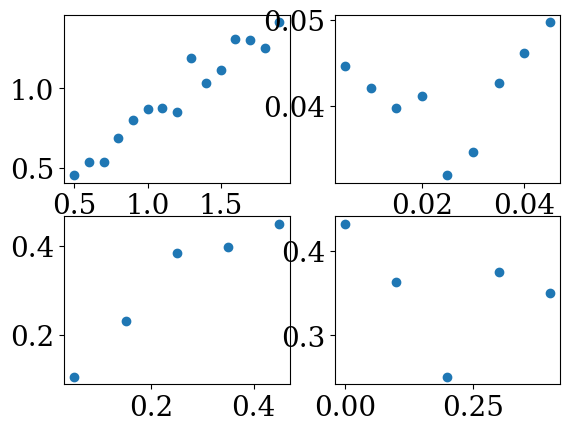

In [ ]:
# theta1data = torch.load(f"D:/s.velut/Documents/These/DCC/SBI/results/flashvep/x_obs_100_{np.round(torch.tensor([1.,0.02, 0.2,0.1]).to(torch.float32).tolist(),decimals=3)}.pkl")

from matplotlib import colormaps as cm

folder = "variate" if variation else "nonvariate"

method = "GAUSS_clip"
diff1 = []
diff2 = []
diff3 = []
diff4 = []
labels = []
for t1 in theta1range:
    theta_true = torch.as_tensor([t1,0.02, 0.2,0.1])
    
    samples = torch.load(f"D:/s.velut/Documents/These/DCC/SBI/results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/ddim_steps_1000/"+folder+f"/posterior_samples_{np.round(torch.tensor([t1,0.02, 0.2,0.1]).to(torch.float32).tolist(),decimals=3)}_n_obs_8_GAUSS_clip.pkl").tolist()
    diff1.append(max(samples,key=samples.count))
plt.subplot(2,2,1)
plt.scatter(theta1range,np.array(diff1)[:,0])

for t2 in theta2range:
    theta_true = torch.as_tensor([1.0,t2,0.2,0.1])
    
    samples = torch.load(f"D:/s.velut/Documents/These/DCC/SBI/results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/ddim_steps_1000/"+folder+f"/posterior_samples_{np.round(torch.tensor([1.0,t2,0.2,0.1]).to(torch.float32).tolist(),decimals=3)}_n_obs_8_GAUSS_clip.pkl").tolist()
    diff2.append(max(samples,key=samples.count))
plt.subplot(2,2,2)
plt.scatter(theta2range,np.array(diff2)[:,1])

for t3 in theta3range:
    theta_true = torch.as_tensor([1.0,0.02,t3,0.1])
    
    samples = torch.load(f"D:/s.velut/Documents/These/DCC/SBI/results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/ddim_steps_1000/"+folder+f"/posterior_samples_{np.round(torch.tensor([1.0,0.02,t3,0.1]).to(torch.float32).tolist(),decimals=3)}_n_obs_8_GAUSS_clip.pkl").tolist()
    diff3.append(max(samples,key=samples.count))
plt.subplot(2,2,3)
plt.scatter(theta3range,np.array(diff3)[:,2])

for t4 in theta4range:
    theta_true = torch.as_tensor([1., 0.02, 0.2,t4])
    
    samples = torch.load(f"D:/s.velut/Documents/These/DCC/SBI/results/flashvep/n_train_50000_n_epochs_5000_lr_0.0001/ddim_steps_1000/"+folder+f"/posterior_samples_{np.round(torch.tensor([1., 0.02, 0.2,t4]).to(torch.float32).tolist(),decimals=3)}_n_obs_8_GAUSS_clip.pkl").tolist()
    diff4.append(max(samples,key=samples.count))
plt.subplot(2,2,4)
plt.scatter(theta4range,np.array(diff4)[:,3])

In [30]:
torch.rand(1)*0.1-0.05+theta_true[0],torch.rand(1)*0.1-0.05+theta_true[0],torch.rand(1)*0.1-0.05+theta_true[0]

(tensor([0.9846]), tensor([1.0105]), tensor([1.0178]))

In [ ]:
theta1data = torch.load(f"D:/s.velut/Documents/These/DCC/SBI/results/flashvep/x_obs_100_{np.round(torch.tensor([1.,0.02, 0.2,0.1]).to(torch.float32).tolist(),decimals=3)}.pkl")
theta1data.shape

C:\Users\s.velut\AppData\Local\Temp\ipykernel_15216\1968549815.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  theta1data = torch.load(f"D:/s.velut/Documents/These/DCC/S

torch.Size([100, 1008])